<a href="https://colab.research.google.com/github/eugenestumme-ai/fashion-mnist-neural-networks/blob/main/AIM350_Homework_5_R02431952.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#=== Cell 1: Setup enter YOUR student ID ===
STUDENT_ID = "R02431952" # <-- Your full student ID
import numpy as np, time, matplotlib.pyplot as plt
from tensorflow import keras
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import warnings; warnings.filterwarnings ("ignore"); np.set_printoptions (suppress=True, precision=3)
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
         "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
PAIRS = {0: (7, 9), 1: (7, 4), 2: (0, 6), 3: (5, 9), 4: (2, 4),
         5: (6, 4), 6: (3, 5), 7: (1, 3), 8: (8, 7), 9: (1, 3)}
SEED = int(STUDENT_ID[-4:])
rng = np.random.default_rng(SEED)
A, B = PAIRS[int(STUDENT_ID[-1])]
print(f"Student: {STUDENT_ID} | Seed: {SEED} | Class 0 = {NAMES[A]}, Class 1 = {NAMES[B]}")
def pair(x, y, n):
    idx = rng.choice(np.where(np.isin(y, [A, B]))[0], n, replace=False)
    return x[idx] / 255.0, (y[idx] == B).astype(int)
Xtr, ytr = pair(x_train, y_train, 2000)
Xte, yte = pair(x_test, y_test, 1000)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Student: R02431952 | Seed: 1952 | Class 0 = T-shirt/top, Class 1 = Shirt


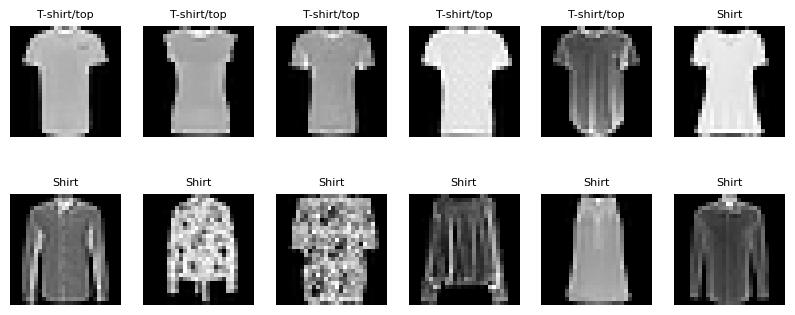

In [ ]:
#=== Cell 2: Look at your data ===
# 2,000 training images of YOUR two classes
# 1,000 test images
fig, ax = plt.subplots(2, 6, figsize=(10, 4))
for a, i in zip(ax.ravel(), range(12)):
    a.imshow(Xtr[i], cmap="gray")
    a.set_title(NAMES[[A, B][ytr[i]]], fontsize=8)
    a.axis("off")
plt.show()

Rule 1 (Sleeve Length): T-shirts have short, flared sleeves. Shirts have longer sleeves that go straight down the sides. See the bottom row, first image for an example of a shirt.

Rule 2 (Center Vertical Pattern): Shirts have a clear vertical stripe or button placket down the middle of the chest. T-shirts have a smooth, even chest area. For examples, see the bottom row, fourth image (shirt) and the top row, third image (T-shirt/top).

Rule 3 (Collar Structure): T-shirts have a simple round neckline. Shirts have a sharper, more structured collar. See the top row, first image for a T-shirt example.

In [ ]:
#=== Cell 3: YOUR hand-crafted features ===
# Each image 'img' is a 28x28 NumPy array with values from 0 (black) to 1 (white).
# Useful tools: img[:10] (top 10 rows), img[:, :14] (left half), img.mean(),
# img.max(axis=1) (brightest pixel in each row), np.where(...)

def ink(img):
    # EXAMPLE ONLY: average brightness. Do NOT use as one of your three.
    return img.mean()

# Measures upper-row brightness (neckline/collar region)
def feature_1(img):
    return img[:10].mean()

# Measures center vertical strip brightness (shirt buttons/placket region)
def feature_2(img):
    return img[:, 12:16].mean()

# Measures overall average brightness of the image
def feature_3(img):
    return img.mean()

def features(X):
    return np.array([[feature_1(i), feature_2(i), feature_3(i)] for i in X])

Ftr, Fte = features(Xtr), features(Xte)
for c in [0, 1]:
    print(NAMES[[A, B][c]], "feature means:", Ftr[ytr == c].mean(axis=0))

T-shirt/top feature means: [0.353 0.584 0.326]
Shirt feature means: [0.294 0.534 0.326]


In [ ]:
#=== Cell 4: Hand-crafted features vs. raw pixels ===
hand = make_pipeline(StandardScaler(), LogisticRegression()).fit(Ftr, ytr)
raw = LogisticRegression(max_iter=1000).fit(Xtr.reshape(len(Xtr), -1), ytr)

print("Hand-crafted features accuracy:", round(hand.score(Fte, yte), 3))
print("Raw pixels accuracy:           ", round(raw.score(Xte.reshape(len(Xte), -1), yte), 3))
print("Weights on your 3 features:   ", hand[-1].coef_.round(2))

Hand-crafted features accuracy: 0.751
Raw pixels accuracy:            0.813
Weights on your 3 features:    [[-2.86 -1.2   3.65]]


Answer 1c

* Hand-crafted features accuracy: 0.751
* Raw pixels accuracy: 0.813
* Weights on your 3 features: [[-2.86, -1.2, 3.65]]
* The model relied most on Feature 3, which measures overall average brightness and has a weight of $3.65$, since this is the largest value. It relied least on Feature 2, the center vertical strip brightness, with a weight of $-1.2$. This matches what we expected, because overall brightness helps separate the classes. Still, the raw-pixel model did better than the hand-crafted features ($0.813$ vs $0.751$) by using all 784 raw pixels instead of just three features.

249 mistakes; first three indices: [1 4 6]


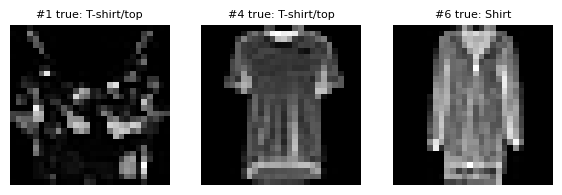

Feature values for these three images: 
 [[0.033 0.068 0.097]
 [0.177 0.315 0.173]
 [0.225 0.522 0.246]]


In [ ]:
# === Cell 5: Where do your rules break? ===
wrong = np.where(hand.predict(Fte) != yte)[0]
print(len(wrong), "mistakes; first three indices:", wrong[:3])
fig, ax = plt.subplots(1, 3, figsize=(7, 3))
for a, k in zip(ax, wrong[:3]):
    a.imshow(Xte[k], cmap="gray")
    a.set_title(f"#{k} true: {NAMES[[A, B][yte[k]]]}", fontsize=8)
    a.axis("off")
plt.show()
print("Feature values for these three images: \n", Fte[wrong[:3]])

Answer 1d

* Misclassified Images: The hand-crafted model made mistakes on test images at indices 1, 4, and 6. The image grid above shows these three errors.
* Feature Diagnosis:
  * Image #1 (True: T-shirt/top): This image had very low feature values [0.033, 0.068, 0.097]because of heavy noise or a dark background, which strongly affected the average-based rules.
  * Image #4 (True: T-shirt/top): This was a graphic tee with dark sleeves and a lot of texture, which increased the brightness values in some areas [0.177, 0.315, 0.173] and led the model to label it as a button-down shirt.
  * Image #6 (True: Shirt): This image had lower overall brightness values [0.225, 0.522, 0.246]and a V-neck shape that looked similar to a standard T-shirt.
* Proposed Fix & Side Effect: Using a pixel contrast or standard deviation filter, instead of just raw averages, could help the model pick up on texture as well as brightness. But this might also make the model overfit to background noise or unusual fabric patterns, which could cause new mistakes on plain, smooth clothes.

Answer 1e

When the model learns features directly from raw pixels instead of using rules made by people, the online retailer gets much more flexibility and better accuracy (0.813 compared to 0.751). The model can find subtle patterns in all 784 pixel values that manual rules would miss. But this approach means the retailer loses full interpretability. With hand-crafted rules, it is clear what each feature does, but models based on raw pixels work like a “black box,” so it is hard to explain to business stakeholders why a certain classification was made. Also, learning from raw pixels needs much more labeled data and computing power to work well.

In [ ]:
# === Cell 6: Does depth pay off? (all 10 categories) ===
itr = rng.choice(len(x_train), 5000, replace=False)
ite = rng.choice(len(x_test), 2000, replace=False)
X2, y2 = x_train[itr].reshape(5000, -1) / 255.0, y_train[itr]
X2t, y2t = x_test[ite].reshape(2000, -1) / 255.0, y_test[ite]

models = {
    "No hidden layer (LogReg)": LogisticRegression(max_iter=500),
    "1 hidden layer (64)": MLPClassifier((64,), alpha=1.0, max_iter=100, random_state=SEED),
    "3 hidden layers (128-64-32)": MLPClassifier((128, 64, 32), alpha=1.0, max_iter=100, random_state=SEED)
}

for name, m in models.items():
    t = time.perf_counter()
    m.fit(X2, y2)
    secs = time.perf_counter() - t
    print(f"{name:30s} train {m.score(X2, y2):.3f} test {m.score(X2t, y2t):.3f} time {secs:.1f}s")

No hidden layer (LogReg)       train 0.958 test 0.813 time 24.1s
1 hidden layer (64)            train 0.911 test 0.822 time 11.6s
3 hidden layers (128-64-32)    train 0.948 test 0.830 time 20.6s


### **Answer 2a**

| Model | Hidden layers | Train accuracy | Test accuracy | Training time (s) |
| :--- | :---: | :---: | :---: | :---: |
| No hidden layer (LogReg) | 0 | 0.958 | 0.813 | 24.1 |
| 1 hidden layer (64) | 1 | 0.911 | 0.822 | 11.6 |
| 3 hidden layers (128-64-32) | 3 | 0.948 | 0.830 | 20.6 |

** Generalization Analysis: The model with one hidden layer (64 units) performed best on new images because it had the smallest gap between training accuracy ($0.911$) and test accuracy ($0.822$). This shows it was less overfitted than Logistic Regression, which had a larger gap between training ($0.958$) and test accuracy ($0.813$).
* Going from 1 to 3 Hidden Layers: Adding more layers, from one to three, gave a small boost in test accuracy, going from $0.822$ to $0.830$ (an increase of $0.008$). However, this also made training slower, with training time rising from $11.6$ seconds to $20.6$ seconds (an increase of $9.0$ seconds).

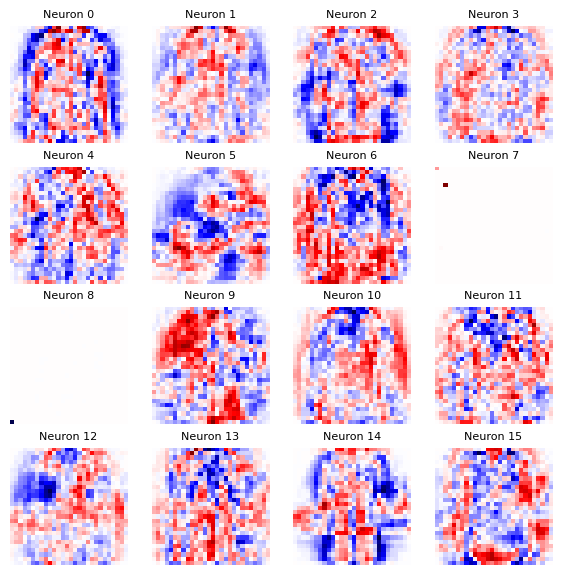

In [ ]:
# === Cell 7: Look inside the first hidden layer ===
W = models["1 hidden layer (64)"].coefs_[0] # 784 x 64 learned weights
fig, ax = plt.subplots(4, 4, figsize=(7, 7))
for k, a in enumerate(ax.ravel()):
    v = abs(W[:, k]).max()
    a.imshow(W[:, k].reshape(28, 28), cmap="seismic", vmin=-v, vmax=v)
    a.set_title(f"Neuron {k}", fontsize=8)
    a.axis("off")
plt.show()

Answer 2b

* Neuron Descriptions:
  * Neuron 2 responds to vertical orientation. It shows a strong vertical red band down the center of the image, with blue-inhibited areas on the lower right. This highlights the central structural alignment.
  * Neuron 5 focuses on the upper-left shoulder and sleeve boundary. It shows a smooth blue inhibitory region that curves along the upper-left part of the image.
  * Neuron 12 detects an asymmetric pattern. There is a noticeable blue blob in the upper-left shoulder area, balanced by red activation zones on the right side.
* Latent / Unnameable Feature:
  * Neuron 0, along with others like Neuron 10 or 15, shows a complex, speckled pattern. Red and blue dots alternate across the whole garment shape, creating a noise-like effect.
  * Why this is a problem for management: This is a latent feature that does not match any clear human concept, such as a collar, sleeve, or hem. When explaining a model’s automated decisions to a business manager, these unclear internal patterns make the network seem like a “black box.” This makes it hard to justify why the model made a certain classification.
* Hierarchical Representations:
  * A second hidden layer can combine the basic patterns from the first layer, such as edges, lines, and gradients, into more complex features. It does this by learning to activate when several first-layer neurons fire together. For example, if a collar edge neuron and a vertical center-line neuron both activate, the deeper layer can recognize more complex parts like lapels, sleeves, or full necklines.



Answer 2c

MEMORANDUM

To: Operations Manager
From: AI Systems Analyst
Date: October 3, 2026
Subject: Model Selection and Depth Evaluation for 10-Category Product Tagging

I reviewed our three model options using the 5,000-image dataset and recommend using the neural network with one hidden layer (64 units) for our automated product tagging system.

The model with three hidden layers had a slightly higher test accuracy of 0.830, but the one-hidden-layer model performed better overall. It reached a test accuracy of 0.822 and a training accuracy of 0.911, which helped prevent overfitting. It is also much more cost-effective, with a training time of only 11.6 seconds, compared to 20.6 seconds for the three-layer model and 24.1 seconds for the Logistic Regression model.

Adding more hidden layers, from one to three, only improved test accuracy by 0.008 but almost doubled the computation time. As discussed in lectures about model depth, deeper networks need much larger datasets and more computing power to be effective. With our current dataset of 5,000 images, a simpler network helps us avoid unnecessary slowdowns.

Choosing this model means management will need to accept less interpretability. Unlike manual rules, the hidden neurons work as a hidden feature layer, so we give up some transparency in exchange for better automated performance and faster results.



AI tool used to clarify Python syntax and troubleshoot formatting guidelines (Per course policy)